# 00 - Get the Dataset and Run Quality Checks (MRL Eye Dataset)

**Part A: get the data** - pick one source in the settings cell:

In [4]:

import os
import zipfile
import requests
from tqdm.auto import tqdm

# Dataset settings
SOURCE = 'official'  # Download official MRL dataset
DATA_DIR = os.environ.get('MRL_DIR', '../data/raw/mrl')

OFFICIAL_URL = 'http://mrl.cs.vsb.cz/data/eyedataset/mrlEyes_2018_01.zip'

os.makedirs(DATA_DIR, exist_ok=True)

ZIP_PATH = os.path.join(DATA_DIR, 'mrlEyes_2018_01.zip')

if SOURCE == 'official':

    if not os.path.exists(ZIP_PATH):
        print("Downloading MRL Eye Dataset...")

        response = requests.get(OFFICIAL_URL, stream=True, timeout=60)
        response.raise_for_status()

        total_size = int(response.headers.get('content-length', 0))

        with open(ZIP_PATH, 'wb') as file:
            with tqdm(total=total_size, unit='B', unit_scale=True) as bar:
                for chunk in response.iter_content(chunk_size=8192):
                    if chunk:
                        file.write(chunk)
                        bar.update(len(chunk))

        print("Download completed!")

    else:
        print("ZIP already exists. Skipping download.")

    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)

    print("Extraction completed!")

print("Dataset location:", os.path.abspath(DATA_DIR))


100%|██████████| 342M/342M [08:03<00:00, 707kB/s]  


Download completed!
Extracting dataset...
Extraction completed!
Dataset location: c:\Users\Admin\OneDrive\Desktop\data\raw\mrl


In [5]:

import os

IMG_EXT = {'.png', '.jpg', '.jpeg', '.bmp'}

image_paths = []

for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if os.path.splitext(file)[1].lower() in IMG_EXT:
            image_paths.append(os.path.join(root, file))

print("Total images:", len(image_paths))

print("\nFirst 5 images:")
for img in image_paths[:5]:
    print(img)


Total images: 84898

First 5 images:
../data/raw/mrl\mrlEyes_2018_01\s0001\s0001_00001_0_0_0_0_0_01.png
../data/raw/mrl\mrlEyes_2018_01\s0001\s0001_00002_0_0_0_0_0_01.png
../data/raw/mrl\mrlEyes_2018_01\s0001\s0001_00003_0_0_0_0_0_01.png
../data/raw/mrl\mrlEyes_2018_01\s0001\s0001_00004_0_0_0_0_0_01.png
../data/raw/mrl\mrlEyes_2018_01\s0001\s0001_00005_0_0_0_0_0_01.png


## Part A. Get the data
Downloading is skipped automatically if `DATA_DIR` already contains images. ZIP files are extracted with a path check so that nothing can be written outside `DATA_DIR`.

In [7]:
def safe_extract(zip_path, dest):
    dest = os.path.abspath(dest)
    with zipfile.ZipFile(zip_path) as z:
        for m in z.infolist():
            target = os.path.abspath(os.path.join(dest, m.filename))
            if not target.startswith(dest + os.sep) and target != dest:
                raise RuntimeError(f'Unsafe path in ZIP: {m.filename}')
        z.extractall(dest)

def download(url, out):
    import requests
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get('content-length', 0))
        with open(out, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True, desc='downloading') as bar:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk); bar.update(len(chunk))

already = len(list_images(DATA_DIR))
if already:
    print(f'{already} images already in {DATA_DIR}: nothing to download.')
elif SOURCE == 'official':
    zip_path = os.path.join(os.path.dirname(os.path.abspath(DATA_DIR)), 'mrlEyes_2018_01.zip')
    download(OFFICIAL_URL, zip_path); safe_extract(zip_path, DATA_DIR)
elif SOURCE == 'kaggle':
    assert KAGGLE_SLUG, 'Set KAGGLE_SLUG first (the owner/name part of the Kaggle dataset URL).'
    if IN_COLAB and not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
        from google.colab import files
        print('Upload kaggle.json'); files.upload()
        os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
        shutil.move('kaggle.json', os.path.expanduser('~/.kaggle/kaggle.json')); os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'], check=True)
    subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_SLUG, '-p', DATA_DIR, '--unzip'], check=True)
elif SOURCE == 'upload':
    zp = LOCAL_ZIP
    if not zp and IN_COLAB:
        from google.colab import files
        print('Choose the dataset .zip'); zp = list(files.upload())[0]
    assert zp and os.path.exists(zp), 'Set LOCAL_ZIP to an existing .zip file (or run on Colab to get an upload button).'
    safe_extract(zp, DATA_DIR)
else:
    print("SOURCE='existing' but no images found: put the images in DATA_DIR or choose another SOURCE.")

paths = list_images(DATA_DIR)
print(f'{len(paths):,} image files found under {DATA_DIR}')


84898 images already in ../data/raw/mrl: nothing to download.
84,898 image files found under ../data/raw/mrl


## Part B. Quality checks
### B1. File inventory
Which extensions are present, and are there non-image files mixed in?

In [8]:
report = {}
all_files = [os.path.join(r, f) for r, _, fs in os.walk(DATA_DIR) for f in fs]
ext = pd.Series([os.path.splitext(f)[1].lower() or '(none)' for f in all_files]).value_counts()
print(ext.to_string())
report['total_files'] = len(all_files); report['image_files'] = len(paths)
report['non_image_files'] = len(all_files) - len(paths)
report['extensions'] = ext.to_dict()
print(f"\n{report['image_files']:,} images, {report['non_image_files']} non-image files (ignored)")

.png    84898
.zip        1
.txt        1
.ods        1

84,898 images, 3 non-image files (ignored)


### B2. Label and metadata check (missing / malformed / invalid)
The label is **inside the filename**, so a bad filename means a missing label. For each image we record whether the name has 8 fields, whether the eye state is `0`/`1`, and whether every other coded field is legal.

In [9]:
COLS = ['subject', 'image_id', 'gender', 'glasses', 'eye_state', 'reflections', 'lighting', 'sensor']
ALLOWED = {'gender': {0, 1}, 'glasses': {0, 1}, 'eye_state': {0, 1}, 'reflections': {0, 1, 2}, 'lighting': {0, 1}, 'sensor': {1, 2, 3}}

rows = []
for p in paths:
    parts = os.path.splitext(os.path.basename(p))[0].strip().split('_')
    rec = {'path': p, 'n_fields': len(parts)}
    if len(parts) == 8: rec.update(dict(zip(COLS, parts)))
    rows.append(rec)
q = pd.DataFrame(rows)
for c in COLS:
    if c not in q: q[c] = np.nan
for c in COLS[1:]: q[c] = pd.to_numeric(q[c], errors='coerce')

q['bad_format']   = q.n_fields != 8
q['missing_label'] = q.eye_state.isna()
q['bad_label']     = q.eye_state.notna() & ~q.eye_state.isin([0, 1])
q['bad_subject']   = ~q.subject.astype(str).str.lower().str.match(r'^s\d+$')
q['bad_values']    = pd.concat([(q[c].notna() & ~q[c].isin(ok)) for c, ok in ALLOWED.items() if c != 'eye_state'], axis=1).any(axis=1)

checks = q[['bad_format', 'missing_label', 'bad_label', 'bad_subject', 'bad_values']].sum().astype(int)
print('Problem counts (rows):'); print(checks.to_string())
print('\nMissing values per field:'); print(q[COLS].isna().sum().to_string())
report['label_checks'] = checks.to_dict()
report['missing_per_field'] = q[COLS].isna().sum().astype(int).to_dict()

bad = q[q[['bad_format', 'missing_label', 'bad_label', 'bad_subject', 'bad_values']].any(axis=1)]
print(f'\n{len(bad)} images with a label/metadata problem.')
if len(bad): print(bad.path.map(os.path.basename).head(10).to_string(index=False))

Problem counts (rows):
bad_format       0
missing_label    0
bad_label        0
bad_subject      0
bad_values       0

Missing values per field:
subject        0
image_id       0
gender         0
glasses        0
eye_state      0
reflections    0
lighting       0
sensor         0

0 images with a label/metadata problem.


### B3. Unreadable / corrupt images, sizes and colour modes
Each image is opened and fully decoded. We also collect the file hash (for duplicates) and the image size / mode (to see format inconsistencies).

In [10]:
def inspect(p):
    rec = {'readable': True}
    try:
        with open(p, 'rb') as f: raw = f.read()
        rec['md5'] = hashlib.md5(raw).hexdigest(); rec['kb'] = len(raw) / 1024
        with Image.open(p) as im:
            rec['mode'] = im.mode; rec['w'], rec['h'] = im.size
            im.load()                           # forces full decode -> catches truncated files
    except Exception as e:
        rec['readable'] = False; rec['error'] = str(e)[:80]
    return rec

q = pd.concat([q, pd.DataFrame([inspect(p) for p in tqdm(q.path)])], axis=1)
print('Unreadable / corrupt images:', int((~q.readable).sum()))
if (~q.readable).any(): print(q.loc[~q.readable, ['path', 'error']].head().to_string(index=False))
ok = q[q.readable]
print('\nColour modes:', ok['mode'].value_counts().to_dict())
print('Distinct image sizes:', ok.groupby(['w', 'h']).ngroups, '| width', ok.w.min(), '-', ok.w.max(), '| height', ok.h.min(), '-', ok.h.max())
report['unreadable'] = int((~q.readable).sum()); report['color_modes'] = ok['mode'].value_counts().to_dict()
report['distinct_sizes'] = int(ok.groupby(['w', 'h']).ngroups)

100%|██████████| 84898/84898 [02:58<00:00, 476.51it/s]


Unreadable / corrupt images: 0

Colour modes: {'L': 84898}
Distinct image sizes: 236 | width 52 - 299 | height 52 - 299


### B4. Duplicates
Identical files are risky: if a copy lands in the test set while the original is in training, the test score is inflated. If the copies carry **different labels**, at least one label is wrong.

In [11]:
dup_rows = int(ok.duplicated('md5').sum())
conf = ok.groupby('md5').eye_state.nunique(); conflicts = int((conf > 1).sum())
print('Exact duplicate files (extra copies):', dup_rows)
print('Duplicate groups with conflicting labels:', conflicts)
report['duplicate_files'] = dup_rows; report['duplicate_groups_conflicting_labels'] = conflicts

Exact duplicate files (extra copies): 38
Duplicate groups with conflicting labels: 33


### B5. First look at class balance and subjects

Class Distribution:
label
open      42952
closed    41946

Imbalance ratio (majority/minority): 1.02

Subjects: 37
Images per subject: min 382 | max 10257


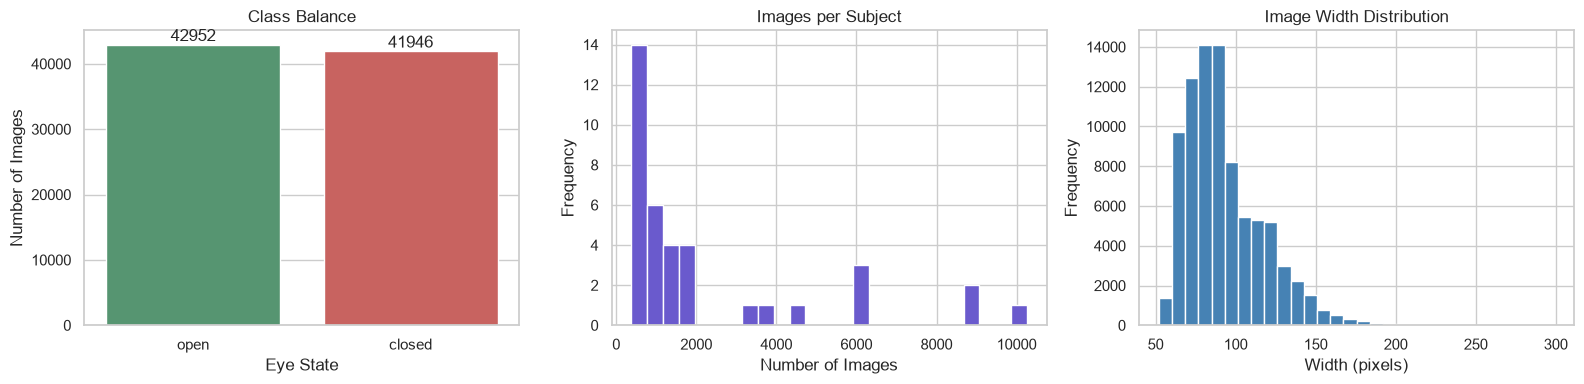

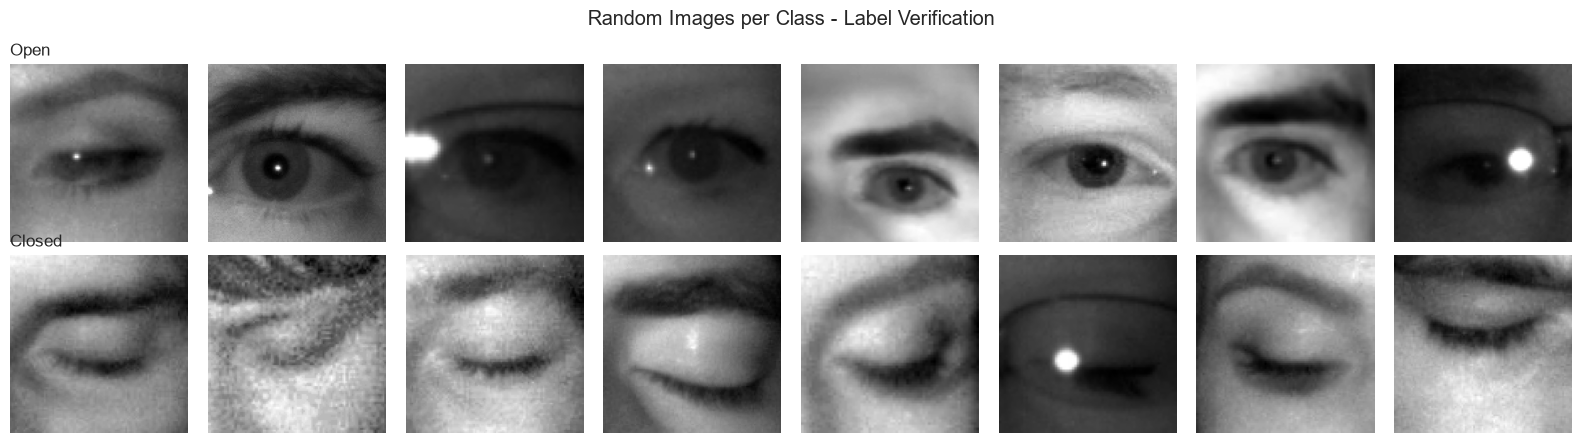


========== QUALITY ANALYSIS SUMMARY ==========
Total usable images: 84898
Open eyes: 42952
Closed eyes: 41946
Total subjects: 37
Saved figures:
../images\quality_01_overview.png
../images\quality_02_samples.png


In [16]:

# ---------------- QUALITY ANALYSIS ----------------

import os
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Ensure images directory exists
IMG_DIR = '../images'
os.makedirs(IMG_DIR, exist_ok=True)

# Save figure function
def savefig(name):
    plt.savefig(
        os.path.join(IMG_DIR, name),
        dpi=150,
        bbox_inches='tight'
    )

# Filter usable images
required_flags = [
    'bad_format',
    'missing_label',
    'bad_label',
    'bad_subject',
    'bad_values'
]

good = q[
    ~q[required_flags].any(axis=1) &
    q['readable'].fillna(False)
].copy()

# Assign class labels
good['label'] = good['eye_state'].map({
    0: 'closed',
    1: 'open'
})

# Remove any unmapped labels
good = good.dropna(subset=['label'])

# ---------------- CLASS DISTRIBUTION ----------------

cnt = good['label'].value_counts()

print("Class Distribution:")
print(cnt.to_string())

if len(cnt) == 2 and cnt.min() > 0:
    ratio = cnt.max() / cnt.min()
    print(f"\nImbalance ratio (majority/minority): {ratio:.2f}")
else:
    ratio = None
    print("\nImbalance ratio cannot be calculated.")

# ---------------- SUBJECT ANALYSIS ----------------

subject_counts = good.groupby('subject').size()

print("\nSubjects:", good['subject'].nunique())

if not subject_counts.empty:
    print("Images per subject: min",
          subject_counts.min(),
          "| max",
          subject_counts.max())

# ---------------- UPDATE REPORT ----------------

report['usable_images'] = int(len(good))
report['class_counts'] = cnt.to_dict()
report['subjects'] = int(good['subject'].nunique())
report['imbalance_ratio'] = float(ratio) if ratio is not None else None

# ---------------- OVERVIEW PLOTS ----------------

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# 1. Class balance
sns.countplot(
    data=good,
    x='label',
    order=['open', 'closed'],
    hue='label',
    palette={
        'open': '#4c9f70',
        'closed': '#d9534f'
    },
    legend=False,
    ax=ax[0]
)

ax[0].set_title('Class Balance')
ax[0].set_xlabel('Eye State')
ax[0].set_ylabel('Number of Images')

for container in ax[0].containers:
    ax[0].bar_label(container)

# 2. Images per subject
if not subject_counts.empty:
    subject_counts.plot.hist(
        bins=25,
        ax=ax[1],
        color='slateblue'
    )

ax[1].set_title('Images per Subject')
ax[1].set_xlabel('Number of Images')

# 3. Image width
q.loc[q['readable'].fillna(False), 'w'].dropna().plot.hist(
    bins=30,
    ax=ax[2],
    color='steelblue'
)

ax[2].set_title('Image Width Distribution')
ax[2].set_xlabel('Width (pixels)')

plt.tight_layout()

savefig('quality_01_overview.png')
plt.show()

# ---------------- RANDOM IMAGE SAMPLES ----------------

fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))

for r, lab in enumerate(['open', 'closed']):

    samples = good[good['label'] == lab]

    n = min(8, len(samples))

    if n == 0:
        ax[r, 0].set_title(f'{lab} (no images)')
        continue

    selected = samples.sample(n=n, random_state=1)

    for c, p in enumerate(selected['path']):

        try:
            img = Image.open(p).convert('L')

            ax[r, c].imshow(img, cmap='gray')
            ax[r, c].axis('off')

        except Exception as e:
            ax[r, c].set_title('Unreadable')
            ax[r, c].axis('off')

    ax[r, 0].set_title(lab.capitalize(), loc='left')

# Hide unused subplot positions
for r, lab in enumerate(['open', 'closed']):
    n = min(8, len(good[good['label'] == lab]))

    for c in range(n, 8):
        ax[r, c].axis('off')

plt.suptitle('Random Images per Class - Label Verification')

plt.tight_layout()

savefig('quality_02_samples.png')
plt.show()

# ---------------- FINAL SUMMARY ----------------

print("\n========== QUALITY ANALYSIS SUMMARY ==========")
print("Total usable images:", len(good))
print("Open eyes:", cnt.get('open', 0))
print("Closed eyes:", cnt.get('closed', 0))
print("Total subjects:", good['subject'].nunique())
print("Saved figures:")
print(os.path.join(IMG_DIR, 'quality_01_overview.png'))
print(os.path.join(IMG_DIR, 'quality_02_samples.png'))


In [18]:

# ---------------- SAVE QUALITY REPORT ----------------

import os
import json

# Ensure processed directory exists
os.makedirs(PROC_DIR, exist_ok=True)

# Save quality report
report_path = os.path.join(PROC_DIR, 'quality_report.json')

with open(report_path, 'w') as f:
    json.dump(report, f, indent=2, default=str)

# Display report
print(json.dumps(report, indent=2, default=str))

# ---------------- DATA VALIDATION ----------------

assert report.get('usable_images', 0) > 0, (
    'No usable images found. Check image labels, metadata and readability.'
)

assert len(cnt) == 2, (
    'Only one class is present. Both open and closed eye images are required.'
)

# ---------------- COUNT DATA ISSUES ----------------

unreadable = report.get('unreadable', 0)
duplicates = report.get('duplicate_files', 0)

label_checks = report.get('label_checks', {})

label_issues = sum(
    value for value in label_checks.values()
    if isinstance(value, (int, float))
)

problems = unreadable + duplicates + label_issues

# ---------------- FINAL VERDICT ----------------

print('\n========== DATA QUALITY VERDICT ==========')

if problems == 0:
    print('VERDICT: Data is clean enough to continue.')
else:
    print(f'VERDICT: {problems} issues found.')
    print('These issues should be removed or handled in 01_cleaning.ipynb.')

print('\nQuality report saved at:')
print(os.path.abspath(report_path))


{
  "total_files": 84901,
  "image_files": 84898,
  "non_image_files": 3,
  "extensions": {
    ".png": 84898,
    ".zip": 1,
    ".txt": 1,
    ".ods": 1
  },
  "label_checks": {
    "bad_format": 0,
    "missing_label": 0,
    "bad_label": 0,
    "bad_subject": 0,
    "bad_values": 0
  },
  "missing_per_field": {
    "subject": 0,
    "image_id": 0,
    "gender": 0,
    "glasses": 0,
    "eye_state": 0,
    "reflections": 0,
    "lighting": 0,
    "sensor": 0
  },
  "unreadable": 0,
  "color_modes": {
    "L": 84898
  },
  "distinct_sizes": 236,
  "duplicate_files": 38,
  "duplicate_groups_conflicting_labels": 33,
  "usable_images": 84898,
  "class_counts": {
    "open": 42952,
    "closed": 41946
  },
  "subjects": 37,
  "imbalance_ratio": 1.0239832165164735
}

========== DATA QUALITY VERDICT ==========
VERDICT: 38 issues found.
These issues should be removed or handled in 01_cleaning.ipynb.

Quality report saved at:
c:\Users\Admin\OneDrive\Desktop\data\processed\quality_report.json

In [ ]:
%pip install numpy pandas matplotlib seaborn pillow tqdm requests scikit-learn opencv-python tensorflow

^C
Note: you may need to restart the kernel to use updated packages.


   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.1 MB/s eta 0:05:20
   ---------------------------------------- 0.5/351.2 MB 1.1 MB/s eta 0:05:20
   ---------------------------------------- 1.0/351.2 MB 1.3 MB/s eta 0:04:28
   ---------------------------------------- 1.3/351.2 MB 1.4 MB/s eta 0:04:04
   ---------------------------------------- 1.6/351.2 MB 1.4 MB/s eta 0:04:14
   ---------------------------------------- 1.8/351.2 MB 1.4 MB/s eta 0:04:18
   ---------------------------------------- 2.4/351.2 MB 1.4 MB/s eta 0:04:17
   ---------------------------------------- 2.6/351.2 MB 1.4 MB/s eta 0:04:18
   ---------------------------------------- 2.9/351.2 MB 1.4 MB/s eta 0:04:16
   ---------------------------------------- 3.1/351.2 MB 1.4 MB/s eta 0:04:16
   ----